# 05 · Interactive Dashboard: Campaign Selection, Budget Scenarios, Segment Analysis

The decision tool is a Streamlit app in [`app/dashboard.py`](../app/dashboard.py). This notebook documents what it shows, verifies that it reproduces notebook 04 **exactly**, and runs a headless smoke test of the app.

```powershell
streamlit run app/dashboard.py
```

#### Design principles
1. **No retraining in the UI.** The app reads frozen test-set artifacts. A slider re-runs only the *allocation rule* on fixed scores and re-values it with fixed AIPW scores. Changing assumptions cannot leak test outcomes into a model.
2. **One code path.** The dashboard and notebook 04 call the same `src/scenario.py` functions, so a number in the app is the number in the report.
3. **Every number is labelled by evidence type:**

| Label | Meaning | Example |
|---|---|---|
| Observed experimental estimate | difference in means / AIPW on randomized data | ATE of the Men's e-mail |
| Held-out policy-value estimate | AIPW value of a policy on the untouched test set | profit of the selected policy at \$3k |
| Model prediction | a fitted model's output | predicted CATE of a segment |
| User-supplied business assumption | an input, not an estimate | margin, cost, budget |
| Simulated scenario | a held-out estimate under assumptions other than the defaults | the budget curve |

#### Views

| Tab | What it answers |
|---|---|
| **Policy comparison** | Under my assumptions, which policy makes the most incremental profit, and how sure are we? |
| **Budget scenarios** | How does profit change with budget, and where do diminishing returns start? How robust is the advantage to margin and cost? |
| **Segment analysis** | Which customer groups respond to which e-mail, and who does the policy target? |
| **Experiment** | What did the randomized test show on average? |
| **Model diagnostics** | How well does each model rank customers on held-out data? |

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config, data, scenario, plotting as P

P.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
frame, meta = scenario.load_artifacts()
print(f"Test customers: {len(frame):,} | uplift models: {meta['uplift_models']} | ranking models: {meta['ranking_models']}")

Test customers: 12,800 | uplift models: ['T-learner', 'Causal forest (leaf 200)', 'X-learner (regularized)'] | ranking models: ['Purchase propensity']


## 1 · Artifact contract

The dashboard receives pre-treatment segment columns, model scores, and AIPW evaluation scores. It does **not** receive raw outcomes (`visit`, `conversion`, `spend`) or the treatment label, so it cannot refit anything.

In [2]:
expected = {f"{m}|{a}" for m in meta["ranking_models"] + meta["uplift_models"] for a in scenario.ARM_ORDER}
expected |= {f"gamma_{o}|{a}" for o in ["spend", "visit"] for a in scenario.ARM_ORDER}
missing = expected - set(frame.columns)
leaked = set(frame.columns) & (set(data.POST_TREATMENT) | {"segment"})
assert not missing, missing
assert not leaked, leaked
assert len(frame) == meta["n_test"]
assert frame.notna().all().all()
print("artifact contract OK:", len(frame.columns), "columns,", len(frame), "rows")

artifact contract OK: 23 columns, 12800 rows


## 2 · The dashboard reproduces notebook 04

In [3]:
nb04 = pd.read_csv(config.ARTIFACTS_DIR / "test_policy_results.csv")
max_abs = 0.0
for opt_key in scenario.CAMPAIGN_OPTIONS:
    now = scenario.run_scenario(frame, meta, opt_key, meta["margin"], meta["cost"], meta["budget"], meta["population"])
    ref = nb04[nb04.option == opt_key].set_index("policy").loc[now.index]
    max_abs = max(max_abs, float(np.abs(now["profit"] - ref["profit"]).max()))
print(f"max |dashboard − notebook 04| profit difference: ${max_abs:.6f}")
assert max_abs < 1e-6

max |dashboard − notebook 04| profit difference: $0.000000


## 3 · Scenario walk-through

Each scenario below is a set of assumptions that a marketing lead might bring to a planning meeting. The table shows what each policy delivers per 100k customers.

In [4]:
SEL = meta["selected_model"]
scen = {
    "Default ($3k, 35%, $0.10)": dict(margin=0.35, cost=0.10, budget=3000),
    "Tight budget ($1k)": dict(margin=0.35, cost=0.10, budget=1000),
    "No budget limit": dict(margin=0.35, cost=0.10, budget=None),
    "Thin margin (20%)": dict(margin=0.20, cost=0.10, budget=3000),
    "Expensive contact ($0.25)": dict(margin=0.35, cost=0.25, budget=7500),
}
rows = []
for name, s in scen.items():
    r = scenario.run_scenario(frame, meta, "best", s["margin"], s["cost"], s["budget"], config.POPULATION_SIZE)
    base = r.drop(index=meta["uplift_models"]).profit
    rows.append({"scenario": name, "Random": r.loc["Random", "profit"], "Purchase propensity": r.loc["Purchase propensity", "profit"],
                 "T-learner": r.loc["T-learner", "profit"], meta["challenger_model"]: r.loc[meta["challenger_model"], "profit"],
                 SEL: r.loc[SEL, "profit"], f"{SEL} coverage": r.loc[SEL, "coverage"],
                 "advantage vs best baseline": r.loc[SEL, "profit"] - base.max()})
walk = pd.DataFrame(rows).set_index("scenario")
money_cols = [c for c in walk.columns if "coverage" not in c]
walk.style.format({**{c: P.money0 for c in money_cols}, f"{SEL} coverage": "{:.0%}"}).set_caption(
    "Best-campaign option · held-out profit per 100k customers")

,Random,Purchase propensity,T-learner,Causal forest (leaf 200),X-learner (regularized),X-learner (regularized) coverage,advantage vs best baseline
scenario,,,,,,,
"Default ($3k, 35%, $0.10)","$2,421",$291,"−$3,208","−$4,941",$377,30%,"−$2,044"
Tight budget ($1k),$807,"$2,840","−$1,851","−$4,590",−$688,10%,"−$3,528"
No budget limit,"$8,070","$8,070","$2,212",−$396,"$6,519",96%,"−$1,552"
Thin margin (20%),$98,"−$1,119","−$3,119","−$4,109","−$1,070",30%,"−$1,168"
Expensive contact ($0.25),"−$2,079","−$4,209","−$7,708","−$9,441","−$4,123",30%,"−$4,123"


## 4 · Segment view (as shown in the app)

segment,customers,observed_mens,observed_womens,predicted_mens,predicted_womens,share_targeted,share_mens,share_womens
both,1324,$2.24,$0.82,$1.14,$0.45,57%,45%,12%
mens only,5802,$0.00,$0.04,$0.84,$0.41,33%,24%,8%
womens only,5674,$0.64,$0.41,$0.74,$0.56,21%,13%,8%


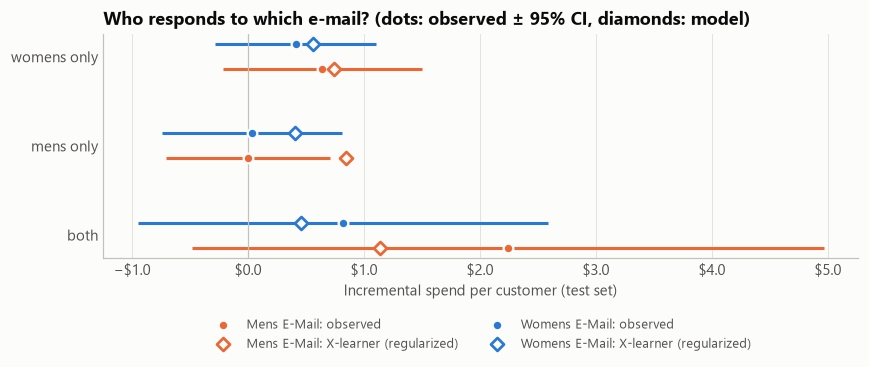

In [5]:
seg = scenario.segment_view(frame, meta, "merch_history", SEL, "best", 0.35, 0.10, 3000)
display(seg[["segment", "customers", "observed_mens", "observed_womens", "predicted_mens", "predicted_womens",
             "share_targeted", "share_mens", "share_womens"]].style.format(
    {"observed_mens": "${:.2f}", "observed_womens": "${:.2f}", "predicted_mens": "${:.2f}", "predicted_womens": "${:.2f}",
     "share_targeted": "{:.0%}", "share_mens": "{:.0%}", "share_womens": "{:.0%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(seg))
for off, a, label in [(-0.14, "mens", "Mens E-Mail"), (0.14, "womens", "Womens E-Mail")]:
    c = P.CAMPAIGN_COLORS[label]
    ax.hlines(y + off, seg[f"lo_{a}"], seg[f"hi_{a}"], color=c, lw=2)
    ax.scatter(seg[f"observed_{a}"], y + off, color=c, s=40, zorder=3, edgecolor=P.SURFACE, linewidth=1.5, label=f"{label}: observed")
    ax.scatter(seg[f"predicted_{a}"], y + off, marker="D", facecolor=P.SURFACE, edgecolor=c, s=36, zorder=4, linewidth=1.8,
               label=f"{label}: {SEL}")
ax.axvline(0, color=P.AXIS, lw=0.8)
ax.set_yticks(y, seg["segment"]); ax.grid(axis="y", visible=False); ax.grid(axis="x"); P.dollar(ax, "x", 1)
ax.set_xlabel("Incremental spend per customer (test set)")
ax.set_title("Who responds to which e-mail? (dots: observed ± 95% CI, diamonds: model)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, fontsize=8.5)
fig.tight_layout(); P.savefig(fig, "05_segment_view"); plt.show()

## 5 · Headless smoke test of the Streamlit app

`streamlit.testing.v1.AppTest` runs the script without a browser. The test checks that every tab renders without an exception and that changing the campaign and budget widgets updates the headline metric.

In [6]:
from streamlit.testing.v1 import AppTest

at = AppTest.from_file(str(ROOT / "app" / "dashboard.py"), default_timeout=180).run()
assert not at.exception, at.exception
print("tabs:", [t.label for t in at.tabs])
print("headline metric:", at.metric[0].label, "=", at.metric[0].value)
first = at.metric[0].value

at.sidebar.radio[0].set_value("womens").run()
at.sidebar.slider[2].set_value(1000.0).run()
assert not at.exception, at.exception
print("after switching to Women's e-mail and $1k budget:", at.metric[0].value)
assert at.metric[0].value != first
print("smoke test passed")

2026-10-19 16:34:36.836 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


tabs: ['Policy comparison', 'Budget scenarios', 'Segment analysis', 'Experiment', 'Model diagnostics', 'About']
headline metric: Causal forest (leaf 200): incremental profit = $2,632


after switching to Women's e-mail and $1k budget: $1,313
smoke test passed
